# Aims 1 and 2 – cell-type classification with frozen DinoBloom-B

Aims, the pre-specified plan, and the results summary are in `classification_benchmark.md`.

In [1]:
import json, time
from pathlib import Path
import numpy as np
import pandas as pd
from PIL import Image
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score, balanced_accuracy_score, confusion_matrix
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name in ("notebooks", "final_project") else Path.cwd()
EMB = ROOT / "data" / "embeddings"
OUT = ROOT / "data" / "benchmark_aims12"
OUT.mkdir(exist_ok=True)
INK, INK2, MUTED, GRID = "#0b0b0b", "#52514e", "#9a9994", "#e4e3df"
plt.rcParams.update({"font.size": 9, "axes.edgecolor": MUTED, "axes.labelcolor": INK2, "xtick.color": INK2,
                     "ytick.color": INK2, "axes.titlecolor": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 80)

# ---- the same cell table and tight-crop embeddings as pilot_existing_crops.ipynb (read only)
cp = pd.read_csv(EMB / "dinobloom_b_letterbox_m05_allCPCML" / "cells.csv", dtype={"patient_id": str})
cp["path"] = [ROOT / "data" / "crops" / p / l / f"{c}.png" for p, l, c in zip(cp["patient_id"], cp["label"], cp["cell_id"])]
ncg = pd.read_csv(EMB / "dinobloom_b_letterbox_m05_nonCML" / "cells.csv", dtype={"patient_id": str})
nco = pd.read_csv(EMB / "dinobloom_b_letterbox_m05_nonCML_allcells" / "cells.csv", dtype={"patient_id": str})
for d in (ncg, nco):
    d["path"] = [ROOT / p for p in d["image_path"]]
cols = ["cell_id", "patient_id", "label", "path"]
cells = pd.concat([cp[cols], ncg[cols], nco[cols]], ignore_index=True)
X_tight = np.vstack([np.load(EMB / "dinobloom_b_letterbox_m05_allCPCML" / "emb_cls.npy"),
                     np.load(EMB / "dinobloom_b_letterbox_m05_nonCML" / "emb_cls.npy"),
                     np.load(EMB / "dinobloom_b_letterbox_m05_nonCML_allcells" / "emb_cls.npy")])
assert len(X_tight) == len(cells) == 28395 and cells["cell_id"].is_unique

cohort = pd.read_csv(ROOT / "data" / "cohort_all245" / "cohort.csv", dtype={"patient_id": str}).set_index("patient_id")
cells["diagnosis"] = cells["patient_id"].map(cohort["diagnosis"])
cells["cpcml"] = cells["diagnosis"].str.contains("Chronic Phase")
age_m = cells["patient_id"].map(cohort["age"]).str.rstrip("M").astype(int)
cells["age_band"] = pd.cut(age_m, [0, 60, 114, 300], labels=["<=5 y", "7-9.5 y", ">=12.5 y"])
print(f"cells: {len(cells)} | patients: {cells['patient_id'].nunique()} | labels: {cells['label'].nunique()}")
print(cells.groupby("age_band", observed=True)["patient_id"].nunique().rename("patients").to_string())

cells: 28395 | patients: 113 | labels: 49
age_band
<=5 y       35
7-9.5 y     22
>=12.5 y    56


### Class schemes (fixed before results)

In [2]:
BMC_MAP = {
    "BLA": ["lymphocytic_blast", "myelocytic_blast", "monocytic_blast", "unknown_blast"],
    "PMO": ["promyelocyte"], "MYB": ["neutrophilic_myelocyte"], "MMZ": ["neutrophilic_metamyelocyte"],
    "NGB": ["neutrophilic_band"], "NGS": ["segmented_neutrophil"],
    "EOS": ["segmented_eosinophil", "eosinophilic_myelocyte", "eosinophilic_metamyelocyte", "eosinophilic_band"],
    "BAS": ["segmented_basophil", "basophilic_myelocyte", "basophilic_metamyelocyte", "basophilic_band"],
    "EBO": ["orthochromatic_erythroblast", "polychromatic_erythroblast", "basophilic_erythroblast"],
    "PEB": ["proerythroblast"],
    "LYT": ["lymphocyte"], "LYI": ["prolymphocyte", "lymphoid_precursor_cell", "lymphoidocyte"],
    "MON": ["monocyte", "promonocyte"], "PLM": ["plasma_cell"],
    "KSC": ["smudge_cell"], "ART": ["artifact"], "NIF": ["damaged_cell", "technically_unfit"],
    "OTH": ["megakaryocyte", "promegakaryocyte", "micromegakaryocyte", "macrophage", "mitosis", "phagocytosis",
            "pseudo_gaucher_cell"],
}
EXCLUDE = {"erythrocyte", "thrombocyte", "giant_platelet", "thrombocyte_aggregate", "spicule",
           "neutrophil_extracellular_trap", "no_consensus_found", "myeloid_precursor_cell",
           "degranulated_neutrophilic_myelocyte", "degranulated_neutrophilic_metamyelocyte"}
lab2bmc = {l: k for k, v in BMC_MAP.items() for l in v}
unmapped = set(cells["label"]) - set(lab2bmc) - EXCLUDE
assert not unmapped, f"labels with no rule: {unmapped}"
cells["bmc"] = cells["label"].map(lab2bmc)

pp = cells[cells["label"] != "no_consensus_found"].groupby("label").agg(n=("cell_id", "size"), pts=("patient_id", "nunique"))
NATIVE = sorted(pp[(pp["n"] >= 50) & (pp["pts"] >= 3)].index)
cells["native"] = cells["label"].where(cells["label"].isin(NATIVE))

tab = cells.dropna(subset=["bmc"]).groupby("bmc").agg(cells=("cell_id", "size"), patients=("patient_id", "nunique"))
print(f"S-BMC: {cells['bmc'].notna().sum()} cells, {tab.shape[0]} classes")
print(tab.sort_values("cells", ascending=False).to_string())
print(f"\nS-native: {cells['native'].notna().sum()} cells, {len(NATIVE)} classes")

S-BMC: 24716 cells, 18 classes
     cells  patients
bmc                 
BLA   7093        91
NIF   3283       113
NGS   2791        75
NGB   1825        65
KSC   1820       105
PMO   1573        64
MYB   1512        69
MMZ    967        66
OTH    944        75
EOS    672        62
ART    663        99
EBO    479        81
LYT    382        91
MON    265        60
BAS    227        49
LYI    127        63
PEB     77        37
PLM     16         9

S-native: 27624 cells, 40 classes


## 1. Full-field embeddings (R-full): stored 320 px crop → 224 px, DinoBloom-B CLS (~10 min, cached)

In [3]:
FULL = OUT / "emb_cls_fullfield.npy"
if FULL.exists():
    X_full = np.load(FULL)
    print("loaded", FULL.name, X_full.shape)
else:
    import torch
    import torch.nn as nn
    from torchvision import transforms
    hub_dir = Path.home() / ".cache" / "torch" / "hub" / "facebookresearch_dinov2_main"
    model = torch.hub.load(str(hub_dir), "dinov2_vitb14", source="local", pretrained=False)
    teacher = torch.load(ROOT / "models" / "DinoBloom-B.pth", map_location="cpu", weights_only=True)["teacher"]
    model.pos_embed = nn.Parameter(torch.zeros(1, 257, 768))
    print(model.load_state_dict({k.replace("backbone.", ""): v for k, v in teacher.items()
                                 if "dino_head" not in k and "ibot_head" not in k}, strict=True))
    device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
    model = model.eval().to(device)
    tf = transforms.Compose([transforms.Resize((224, 224), interpolation=transforms.InterpolationMode.BICUBIC),
                             transforms.ToTensor(),
                             transforms.Normalize((0.485, 0.456, 0.406), (0.229, 0.224, 0.225))])
    out, t0 = [], time.time()
    with torch.no_grad():
        for s in range(0, len(cells), 64):
            x = torch.stack([tf(Image.open(p).convert("RGB")) for p in cells["path"].iloc[s:s + 64]]).to(device)
            out.append(model(x).cpu())
            if (s // 64) % 100 == 0:
                print(f"  {s + len(x)} / {len(cells)}  {time.time() - t0:.0f} s", flush=True)
    X_full = torch.cat(out).numpy().astype(np.float32)
    np.save(FULL, X_full)
    json.dump({"what": "DinoBloom-B CLS of the stored 320 px crop resized to 224 px (bicubic), ImageNet normalisation",
               "rows": "cells in the order of allCPCML + nonCML + nonCML_allcells cells.csv", "device": str(device),
               "created": time.strftime("%Y-%m-%d"), "seconds": round(time.time() - t0)},
              open(OUT / "provenance.json", "w"), indent=1)
    print(f"embedded {len(X_full)} crops in {time.time() - t0:.0f} s on {device}")
assert X_full.shape == (len(cells), 768)

/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/Users/abishekchozhan/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


<All keys matched successfully>


  64 / 28395  2 s


  6464 / 28395  125 s


  12864 / 28395  251 s


  19264 / 28395  381 s


  25664 / 28395  512 s


embedded 28395 crops in 568 s on mps


## 2. Classification: 1-NN, 20-NN, linear probe × patient-grouped and cell-level splits

In [4]:
def l2(X):
    return X / np.linalg.norm(X, axis=1, keepdims=True)


CLFS = {
    "1-NN": lambda: KNeighborsClassifier(1, metric="cosine", algorithm="brute"),
    "20-NN": lambda: KNeighborsClassifier(20, metric="cosine", algorithm="brute"),
    "linear probe": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=3000)),
}
REPS = {"R-full": X_full, "R-tight": X_tight}
SCHEMES = ["bmc", "native"]


def folds(sub, split):
    y, g = sub["y"].to_numpy(), sub["patient_id"].to_numpy()
    if split == "patient":
        return list(StratifiedGroupKFold(5, shuffle=True, random_state=0).split(np.zeros(len(y)), y, g))
    return list(StratifiedKFold(5, shuffle=True, random_state=0).split(np.zeros(len(y)), y))


PRED = OUT / "oof_predictions.parquet"
if PRED.exists():
    preds = pd.read_parquet(PRED)
    print("loaded", PRED.name, preds.shape)
else:
    rows, t0 = [], time.time()
    for scheme in SCHEMES:
        sub = cells.dropna(subset=[scheme]).copy()
        sub["y"] = sub[scheme]
        idx = sub.index.to_numpy()
        for split in ("patient", "cell"):
            F = folds(sub, split)
            for rep, X in REPS.items():
                Xs = l2(X[idx])
                for name, make in CLFS.items():
                    yhat = np.empty(len(sub), dtype=object)
                    for k, (tr, te) in enumerate(F):
                        m = make().fit(Xs[tr], sub["y"].to_numpy()[tr])
                        yhat[te] = m.predict(Xs[te])
                    rows.append(pd.DataFrame({"cell_id": sub["cell_id"].to_numpy(), "scheme": scheme, "split": split,
                                              "rep": rep, "clf": name, "y": sub["y"].to_numpy(), "yhat": yhat.astype(str)}))
                    print(f"{scheme:6s} {split:7s} {rep:7s} {name:12s} done ({time.time() - t0:.0f} s)", flush=True)
    preds = pd.concat(rows, ignore_index=True)
    preds.to_parquet(PRED)
preds = preds.merge(cells[["cell_id", "patient_id", "cpcml", "age_band"]], on="cell_id")

bmc    patient R-full  1-NN         done (4 s)


bmc    patient R-full  20-NN        done (10 s)


bmc    patient R-full  linear probe done (27 s)


bmc    patient R-tight 1-NN         done (31 s)


bmc    patient R-tight 20-NN        done (37 s)


bmc    patient R-tight linear probe done (53 s)


... (14 outputs left out)

native cell    R-full  linear probe done (226 s)


native cell    R-tight 1-NN         done (235 s)


native cell    R-tight 20-NN        done (245 s)


native cell    R-tight linear probe done (272 s)


In [5]:
def metrics(d):
    return pd.Series({"wF1": 100 * f1_score(d["y"], d["yhat"], average="weighted"),
                      "Acc": 100 * accuracy_score(d["y"], d["yhat"]),
                      "bAcc": 100 * balanced_accuracy_score(d["y"], d["yhat"])})


res = preds.groupby(["scheme", "split", "rep", "clf"], sort=False).apply(metrics).round(1)
order = {"1-NN": 0, "20-NN": 1, "linear probe": 2}
wide = res.unstack("clf")
wide = wide.reindex(columns=sorted(wide.columns, key=lambda c: (order[c[1]], ["wF1", "Acc", "bAcc"].index(c[0]))))
wide.columns = [f"{c[1]} {c[0]}" for c in wide.columns]
wide.to_csv(OUT / "results_all.csv")
print(wide.to_string())

                        1-NN wF1  1-NN Acc  1-NN bAcc  20-NN wF1  20-NN Acc  20-NN bAcc  linear probe wF1  linear probe Acc  linear probe bAcc
scheme split   rep                                                                                                                            
bmc    patient R-full       63.3      63.8       50.2       68.7       70.7        50.5              68.9              68.9               56.2
               R-tight      66.1      66.5       53.6       71.7       73.4        53.8              71.2              71.1               59.5
       cell    R-full       57.0      57.3       43.6       69.2       71.1        51.6              71.2              71.3               59.0
               R-tight      67.4      67.8       56.8       72.6       74.2        56.8              72.8              72.9               62.0
native patient R-full       57.3      58.0       36.4       62.8       66.2        37.8              63.7              63.6               43.4

### 95% confidence intervals for the primary rows (patient-cluster bootstrap, 1,000 resamples)

In [6]:
rng = np.random.default_rng(0)
ci_rows = []
for (scheme, rep, clf), d in preds[preds["split"] == "patient"].groupby(["scheme", "rep", "clf"]):
    by_p = {p: g for p, g in d.groupby("patient_id")}
    pts = np.array(list(by_p))
    boot = []
    for _ in range(1000):
        s = pd.concat([by_p[p] for p in rng.choice(pts, len(pts))])
        boot.append(metrics(s))
    boot = pd.DataFrame(boot)
    point = metrics(d)
    for m in ["wF1", "Acc", "bAcc"]:
        ci_rows.append({"scheme": scheme, "rep": rep, "clf": clf, "metric": m, "value": point[m],
                        "lo": boot[m].quantile(0.025), "hi": boot[m].quantile(0.975)})
ci = pd.DataFrame(ci_rows)
ci["value (95% CI)"] = [f"{v:.1f} ({a:.1f}-{b:.1f})" for v, a, b in zip(ci["value"], ci["lo"], ci["hi"])]
ci_w = ci.pivot_table(index=["scheme", "rep", "clf"], columns="metric", values="value (95% CI)", aggfunc="first")[["wF1", "Acc", "bAcc"]]
ci_w.to_csv(OUT / "results_patient_split_ci.csv")
print(ci_w.to_string())

/Users/abishekchozhan/Documents/projects/peds_heme_onc/peds-leukemia/.venv/lib/python3.11/site-packages/sklearn/metrics/_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


metric                                    wF1               Acc              bAcc
scheme rep     clf                                                               
bmc    R-full  1-NN          63.3 (60.9-65.6)  63.8 (61.5-66.2)  50.2 (47.6-52.3)
               20-NN         68.7 (66.7-70.6)  70.7 (68.8-72.7)  50.5 (48.6-52.7)
               linear probe  68.9 (66.7-71.3)  68.9 (66.7-71.3)  56.2 (54.5-58.2)
       R-tight 1-NN          66.1 (63.9-68.2)  66.5 (64.3-68.6)  53.6 (51.1-55.5)
               20-NN         71.7 (69.9-73.8)  73.4 (71.5-75.5)  53.8 (52.1-55.3)
               linear probe  71.2 (69.3-73.1)  71.1 (69.2-73.0)  59.5 (57.0-61.3)
native R-full  1-NN          57.3 (54.9-59.7)  58.0 (55.6-60.4)  36.4 (34.9-37.8)
               20-NN         62.8 (60.4-65.0)  66.2 (63.8-68.4)  37.8 (36.3-39.1)
               linear probe  63.7 (61.3-66.2)  63.6 (61.3-66.1)  43.4 (41.7-44.8)
       R-tight 1-NN          62.0 (59.5-64.5)  62.7 (60.2-65.2)  42.2 (40.6-43.6)
               2

## 3. Aim 2 – side by side with the published BMC numbers (descriptive)

In [7]:
paper = pd.DataFrame({"1-NN wF1": [79.6], "1-NN Acc": [79.5], "1-NN bAcc": [65.8],
                      "20-NN wF1": [83.7], "20-NN Acc": [84.1], "20-NN bAcc": [57.1],
                      "linear probe wF1": [85.5], "linear probe Acc": [85.6], "linear probe bAcc": [70.7]},
                     index=["DinoBloom-B on BMC (paper; adult; 21 classes; 80/20 split; BMC train split in pre-training)"])
ours = wide.loc[("bmc", ["patient", "cell"], "R-full")].copy()
ours.index = [f"DinoBloom-B here (paediatric; {tab.shape[0]} BMC-mapped classes; {s}-level 5-fold; R-full)"
              for s in ours.index.get_level_values("split")]
cmp_ = pd.concat([paper, ours])
cmp_.to_csv(OUT / "aim2_comparison.csv")
print(cmp_.T.to_string())

                   DinoBloom-B on BMC (paper; adult; 21 classes; 80/20 split; BMC train split in pre-training)  DinoBloom-B here (paediatric; 18 BMC-mapped classes; patient-level 5-fold; R-full)  DinoBloom-B here (paediatric; 18 BMC-mapped classes; cell-level 5-fold; R-full)
1-NN wF1                                                                                                  79.6                                                                                63.3                                                                             57.0
1-NN Acc                                                                                                  79.5                                                                                63.8                                                                             57.3
1-NN bAcc                                                                                                 65.8                                                              

## 4. Where the errors are – primary linear probe (S-BMC, R-full, patient-level)

     cells  patients  recall     F1
BLA   7093        91   0.878  0.875
NIF   3283       113   0.487  0.494
NGS   2791        75   0.802  0.795
NGB   1825        65   0.565  0.575
KSC   1820       105   0.654  0.650
PMO   1573        64   0.708  0.695
MYB   1512        69   0.447  0.470
MMZ    967        66   0.430  0.431
OTH    944        75   0.883  0.878
EOS    672        62   0.725  0.735
ART    663        99   0.612  0.591
EBO    479        81   0.833  0.840
LYT    382        91   0.351  0.324
MON    265        60   0.257  0.223
BAS    227        49   0.639  0.673
LYI    127        63   0.142  0.146
PEB     77        37   0.584  0.638
PLM     16         9   0.125  0.222


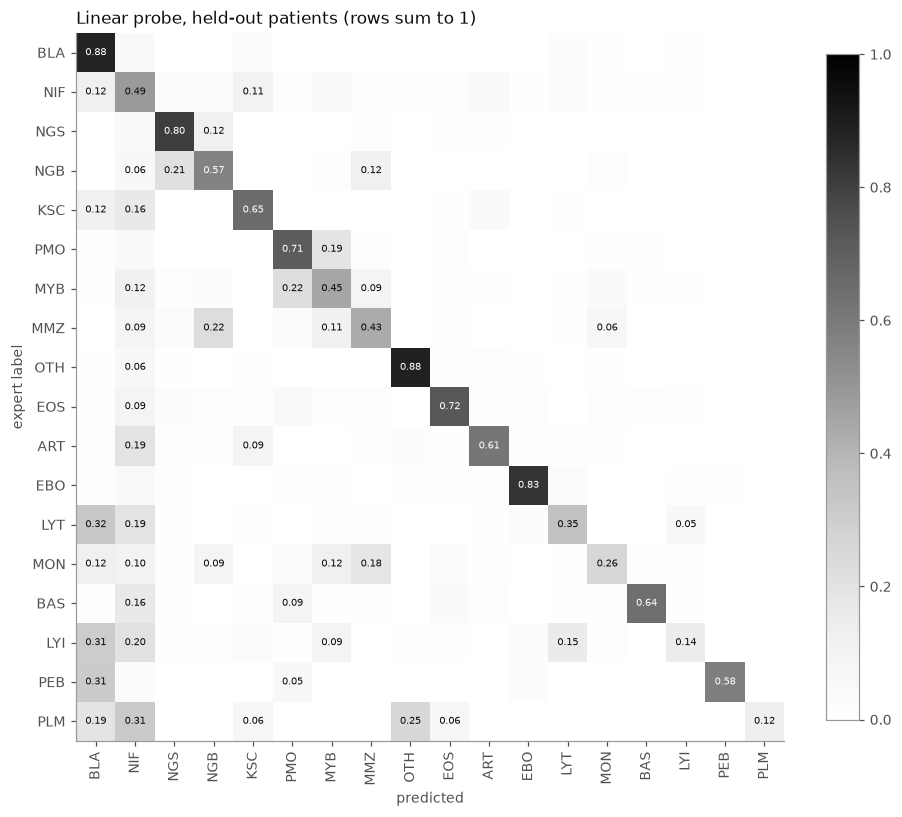

In [8]:
prim = preds[(preds["scheme"] == "bmc") & (preds["split"] == "patient") & (preds["rep"] == "R-full") & (preds["clf"] == "linear probe")]
classes = tab.sort_values("cells", ascending=False).index.tolist()
f1s = f1_score(prim["y"], prim["yhat"], labels=classes, average=None)
rec = [((prim["y"] == c) & (prim["yhat"] == c)).sum() / (prim["y"] == c).sum() for c in classes]
pc = pd.DataFrame({"cells": tab.loc[classes, "cells"], "patients": tab.loc[classes, "patients"],
                   "recall": np.round(rec, 3), "F1": np.round(f1s, 3)}, index=classes)
pc.to_csv(OUT / "per_class_primary.csv")
print(pc.to_string())

cm = confusion_matrix(prim["y"], prim["yhat"], labels=classes, normalize="true")
fig, ax = plt.subplots(figsize=(8.5, 7.5))
im = ax.imshow(cm, cmap="Greys", vmin=0, vmax=1)
ax.set_xticks(range(len(classes)), classes, rotation=90)
ax.set_yticks(range(len(classes)), classes)
for i in range(len(classes)):
    for j in range(len(classes)):
        if cm[i, j] >= 0.05:
            ax.text(j, i, f"{cm[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if cm[i, j] > 0.5 else INK)
ax.set_xlabel("predicted")
ax.set_ylabel("expert label")
ax.set_title("Linear probe, held-out patients (rows sum to 1)", loc="left")
plt.colorbar(im, fraction=0.04)
plt.tight_layout()
plt.show()

## 5. By age band and by diagnosis – primary linear probe

In [9]:
def sub_metrics(d):
    m = metrics(d)
    return pd.Series({"patients": d["patient_id"].nunique(), "cells": len(d), "wF1": round(m["wF1"], 1),
                      "bAcc": round(m["bAcc"], 1)})


by_age = prim.groupby("age_band", observed=True).apply(sub_metrics)
by_dx = prim.assign(group=np.where(prim["cpcml"], "CP-CML", "other diagnoses")).groupby("group").apply(sub_metrics)
print("By age band:\n" + by_age.to_string())
print("\nBy diagnosis:\n" + by_dx.to_string())
print("\nNote: bAcc averages over the classes present in each subgroup, so subgroups with different class mixes are not strictly comparable.")
pd.concat({"age": by_age, "diagnosis": by_dx}).to_csv(OUT / "subgroups_primary.csv")

By age band:
          patients    cells   wF1  bAcc
age_band                               
<=5 y         35.0   6075.0  74.0  54.9
7-9.5 y       22.0   5544.0  65.8  57.0
>=12.5 y      56.0  13097.0  67.9  56.0

By diagnosis:
                 patients    cells   wF1  bAcc
group                                         
CP-CML               46.0  13516.0  63.8  54.1
other diagnoses      67.0  11200.0  75.2  51.7

Note: bAcc averages over the classes present in each subgroup, so subgroups with different class mixes are not strictly comparable.


## 6. Plain DINOv2 (ImageNet) baseline – switched off until the download is approved

In [10]:
APPROVE_DINOV2_DOWNLOAD = False
if not APPROVE_DINOV2_DOWNLOAD:
    print("DINOv2 baseline skipped (download not approved).")

DINOv2 baseline skipped (download not approved).


## Summary

See `classification_benchmark.md`.